# 04 · Skip-logic leakage and leak-free predictability (Fig. 2)
**Question.** How much does each data layer add, and how badly does the questionnaire's skip logic
inflate naive results?

**Method.** Logistic regression, random forest, CatBoost and kNN label interpolation under spatial block
CV (5 seeds x 5 folds; buffers 0-2 km) and leave-one-municipality-out, with imputation and scaling
fitted inside each fold (`src/benchmark.py`); fold-matched tier differences with the corrected resampled
t-test and Holm adjustment; within-ward ranking skill from the out-of-fold predictions.

Running this notebook reproduces the full benchmark. The per-fold results are checkpointed: from scratch
this takes about an hour on a laptop CPU, with existing checkpoints it finishes in seconds and recomputes
only the summary tables.

In [1]:
import logging, os, sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s [%(levelname)s] %(message)s", stream=sys.stdout, force=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

M = ROOT / "results/metrics"
F = ROOT / "results/figures"

def table(name, **kw):
    return pd.read_csv(M / name, **kw).round(4)

def fig(name, width=1100):
    display(Image(filename=str(F / name), width=width))

In [2]:
from src.benchmark import PROFILES, run_profile

for profile in PROFILES:
    run_profile(profile)
print("benchmark folds up to date")

2026-11-10 15:53:48,929 [INFO] Resuming main: 100 folds already done


2026-11-10 15:53:49,061 [INFO] [env] 5689 sources, 23 features, 0 imputed values


2026-11-10 15:53:49,200 [INFO] [env_hydro] 5689 sources, 39 features, 0 imputed values


2026-11-10 15:53:49,351 [INFO] Resuming features: 50 folds already done


2026-11-10 15:53:49,484 [INFO] [leaky_reference] 5689 sources, 26 features, 0 imputed values


2026-11-10 15:53:49,544 [INFO] [env_hydro_season] 5689 sources, 40 features, 0 imputed values


... (6 outputs left out)

2026-11-10 15:53:50,536 [INFO] [env] 5689 sources, 23 features, 0 imputed values


2026-11-10 15:53:50,654 [INFO] [env_hydro] 5689 sources, 39 features, 0 imputed values


2026-11-10 15:53:50,775 [INFO] [env_rich] 5689 sources, 67 features, 630 imputed values


benchmark folds up to date

## Summary tables (also written to results/metrics)

In [3]:
from src.report import CORE_ORDER, current_runs, load_folds, lomo_table, paired_tests, summarise
from src.features import missingness_audit, single_feature_rule_scores
from src.dataset import load_master

df = load_master()
folds = current_runs(load_folds())
summary = summarise(folds)
summary.to_csv(M / "benchmark_summary.csv", index=False)
tests = pd.concat([paired_tests(folds, None, CORE_ORDER, m) for m in ["roc_auc", "pr_auc"]])
tests.to_csv(M / "paired_tests_vs_best_tabular.csv", index=False)
missingness_audit(df).to_csv(M / "leakage_audit.csv", index=False)
single_feature_rule_scores(df).to_csv(M / "single_feature_auc.csv", index=False)
lomo = lomo_table(folds, df)
summary.pivot_table(index=["profile", "feature_set", "buffer_m"], columns="model", values="roc_auc_mean").round(3)

model                               CatBoost  Logistic Regression  Random Forest  kNN label interpolation
profile  feature_set      buffer_m                                                                       
buffers  env_hydro        1000.0       0.662                0.663          0.671                      NaN
                          2000.0       0.644                0.650          0.652                      NaN
         env_rich         1000.0       0.667                0.657          0.678                      NaN
                          2000.0       0.643                0.641          0.658                      NaN
enriched env_rich         0.0          0.684                0.664          0.693                      NaN
                          500.0        0.681                0.662          0.690                      NaN
features env_hydro_season 0.0          0.748                0.737            NaN                      NaN
         leaky_reference  0.0          0.987                0.986            NaN                      NaN
lomo     env              500.0        0.580                0.586          0.581                    0.513
         env_hydro        500.0        0.638                0.630          0.635                    0.513
         env_rich         500.0        0.631                0.631          0.642                    0.513
main     env              0.0          0.636                0.634          0.638                    0.598
                          500.0        0.618                0.634          0.629                    0.595
         env_hydro        0.0          0.678                0.669          0.683                    0.598
                          500.0        0.674                0.668          0.681                    0.595

## Leakage: outcome-dependent fields and the one-question model

In [4]:
a = table("leakage_audit.csv")
print(f"{int(a.skip_logic_leak.sum())} of {len(a)} processed fields differ in missingness by > 5 percentage points")
a[a.skip_logic_leak].sort_values("missingness_gap", ascending=False).head(12)

55 of 150 processed fields differ in missingness by > 5 percentage points


,column,missing_active,missing_dried,missingness_gap,skip_logic_leak
1,water_quality_ordinal,0.0000,1.0,1.0000,True
2,has_user_group,0.0000,1.0,1.0000,True
3,in_use,0.0000,1.0,1.0000,True
5,water_quality,0.0000,1.0,1.0000,True
4,water_quality_change,0.0000,1.0,1.0000,True
6,Are there water user groups for management?_binary,0.0000,1.0,1.0000,True
7,Is this source in use?_binary,0.0000,1.0,1.0000,True
10,Is water source significant for cultural/religious purpose?_binary,0.0005,1.0,0.9995,True
9,cultural_significance,0.0005,1.0,0.9995,True
14,is_tapped,0.0010,1.0,0.9990,True


In [5]:
table("single_feature_auc.csv").head(10)

,feature,single_feature_auc
0,earthquake_impact_ordinal,0.9584
1,earthquake_impact_known,0.9584
2,Perennial / Seasonal_encoded,0.6518
3,longitude,0.6113
4,precip_monsoon_mm,0.6074
5,precip_annual_mm,0.6049
6,ndvi_mean,0.5868
7,elevation_m,0.5861
8,ndwi_mean,0.5767
9,Source Type_encoded,0.5528


## Tier increments, model comparisons and fold spread

In [6]:
from src.revision_experiments import run as run_experiments
run_experiments(only=["X1", "X2", "X11"])

2026-11-10 15:53:51,405 [INFO] X1 ...


2026-11-10 15:53:51,478 [INFO] 
                                       design                model       from         to  auc_from  auc_to  mean_diff  ci95_low  ci95_high  wins  n_pairs  p_corrected  p_holm
0                       spatial CV, no buffer  Logistic Regression        env  env_hydro    0.6340  0.6688     0.0348   -0.0013     0.0710    23       25       0.0584  0.2919
1                       spatial CV, no buffer  Logistic Regression  env_hydro   env_rich    0.6688  0.6639    -0.0049   -0.0376     0.0277    13       25       0.7572  1.0000
2                       spatial CV, no buffer  Logistic Regression        env   env_rich    0.6340  0.6639     0.0299   -0.0211     0.0809    20       25       0.2386  0.9546
3                       spatial CV, no buffer        Random Forest        env  env_hydro    0.6384  0.6830     0.0446    0.0109     0.0784    23       25       0.0118  0.1058
4                       spatial CV, no buffer        Random Forest  env_hydro   env_rich    0

2026-11-10 15:53:51,479 [INFO] X2 ...


2026-11-10 15:53:56,345 [INFO] 
                      model feature_set  buffer_m  pooled_auc  pooled_sd  within_ward_auc  within_ward_sd  ward_mean_prediction_auc  n_seeds
0                  CatBoost         env       0.0      0.6409     0.0111           0.5851          0.0106                    0.6340        5
1                  CatBoost         env     500.0      0.6238     0.0071           0.5758          0.0130                    0.6234        5
2                  CatBoost   env_hydro       0.0      0.6808     0.0111           0.6414          0.0132                    0.6468        5
3                  CatBoost   env_hydro     500.0      0.6745     0.0089           0.6353          0.0071                    0.6435        5
4       Logistic Regression         env       0.0      0.6479     0.0070           0.5904          0.0109                    0.6263        5
5       Logistic Regression         env     500.0      0.6467     0.0042           0.5904          0.0110                 

2026-11-10 15:53:56,346 [INFO] X11 ...


2026-11-10 15:54:01,443 [INFO] 
                      model feature_set        subset  pooled_auc  pooled_sd  within_ward_auc  within_ward_sd  n_seeds
0                  CatBoost         env   all sources      0.6409     0.0111           0.5851          0.0106        5
1                  CatBoost         env  springs only      0.6256     0.0133           0.5566          0.0105        5
2                  CatBoost   env_hydro   all sources      0.6808     0.0111           0.6414          0.0132        5
3                  CatBoost   env_hydro  springs only      0.6662     0.0104           0.6185          0.0136        5
4       Logistic Regression         env   all sources      0.6479     0.0070           0.5904          0.0109        5
5       Logistic Regression         env  springs only      0.6276     0.0064           0.5598          0.0131        5
6       Logistic Regression   env_hydro   all sources      0.6804     0.0095           0.6420          0.0102        5
7       Logistic

In [7]:
x1 = table("x1_tier_increments.csv")
x1[["design", "model", "from", "to", "auc_from", "auc_to", "mean_diff", "ci95_low", "ci95_high", "p_holm"]]

,design,model,from,to,auc_from,auc_to,mean_diff,ci95_low,ci95_high,p_holm
0,"spatial CV, no buffer",Logistic Regression,env,env_hydro,0.6340,0.6688,0.0348,-0.0013,0.0710,0.2919
1,"spatial CV, no buffer",Logistic Regression,env_hydro,env_rich,0.6688,0.6639,-0.0049,-0.0376,0.0277,1.0000
2,"spatial CV, no buffer",Logistic Regression,env,env_rich,0.6340,0.6639,0.0299,-0.0211,0.0809,0.9546
3,"spatial CV, no buffer",Random Forest,env,env_hydro,0.6384,0.6830,0.0446,0.0109,0.0784,0.1058
4,"spatial CV, no buffer",Random Forest,env_hydro,env_rich,0.6830,0.6930,0.0100,-0.0133,0.0333,1.0000
5,"spatial CV, no buffer",Random Forest,env,env_rich,0.6384,0.6930,0.0546,0.0096,0.0996,0.1549
6,"spatial CV, no buffer",CatBoost,env,env_hydro,0.6357,0.6778,0.0420,0.0014,0.0827,0.2587
7,"spatial CV, no buffer",CatBoost,env_hydro,env_rich,0.6778,0.6842,0.0064,-0.0261,0.0390,1.0000
8,"spatial CV, no buffer",CatBoost,env,env_rich,0.6357,0.6842,0.0485,0.0051,0.0919,0.2099
9,"spatial CV, 500 m buffer",Logistic Regression,env,env_hydro,0.6336,0.6680,0.0344,-0.0014,0.0702,0.2962


In [8]:
display(table("x2_within_ward_auc.csv"))
display(table("x11_lomo_by_municipality.csv").query("feature_set == 'env_hydro'"))
table("x11_springs_only_auc.csv")

,model,feature_set,buffer_m,pooled_auc,pooled_sd,within_ward_auc,within_ward_sd,ward_mean_prediction_auc,n_seeds
0,CatBoost,env,0.0,0.6409,0.0111,0.5851,0.0106,0.6340,5
1,CatBoost,env,500.0,0.6238,0.0071,0.5758,0.0130,0.6234,5
2,CatBoost,env_hydro,0.0,0.6808,0.0111,0.6414,0.0132,0.6468,5
3,CatBoost,env_hydro,500.0,0.6745,0.0089,0.6353,0.0071,0.6435,5
4,Logistic Regression,env,0.0,0.6479,0.0070,0.5904,0.0109,0.6263,5
5,Logistic Regression,env,500.0,0.6467,0.0042,0.5904,0.0110,0.6249,5
6,Logistic Regression,env_hydro,0.0,0.6804,0.0095,0.6420,0.0102,0.6371,5
7,Logistic Regression,env_hydro,500.0,0.6794,0.0095,0.6393,0.0097,0.6377,5
8,kNN label interpolation,env,0.0,0.5960,0.0224,0.5116,0.0111,0.6137,5
9,kNN label interpolation,env,500.0,0.6013,0.0239,0.4968,0.0143,0.6294,5


,municipality,feature_set,model,auc_mean,auc_sd_over_seeds,n_test,test_prevalence
4,Bethanchownk,env_hydro,CatBoost,0.6702,0.0090,385.0,0.1922
5,Bethanchownk,env_hydro,Logistic Regression,0.6672,0.0494,385.0,0.1922
6,Bethanchownk,env_hydro,Random Forest,0.6325,0.0142,385.0,0.1922
7,Bethanchownk,env_hydro,kNN label interpolation,0.5411,0.0125,385.0,0.1922
16,Dhulikhel,env_hydro,CatBoost,0.6051,0.0182,1174.0,0.2879
17,Dhulikhel,env_hydro,Logistic Regression,0.6014,0.0174,1174.0,0.2879
18,Dhulikhel,env_hydro,Random Forest,0.5872,0.0181,1174.0,0.2879
19,Dhulikhel,env_hydro,kNN label interpolation,0.5014,0.0154,1174.0,0.2879
28,Namobuudha,env_hydro,CatBoost,0.5919,0.0173,478.0,0.2008
29,Namobuudha,env_hydro,Logistic Regression,0.5933,0.0068,478.0,0.2008


,model,feature_set,subset,pooled_auc,pooled_sd,within_ward_auc,within_ward_sd,n_seeds
0,CatBoost,env,all sources,0.6409,0.0111,0.5851,0.0106,5
1,CatBoost,env,springs only,0.6256,0.0133,0.5566,0.0105,5
2,CatBoost,env_hydro,all sources,0.6808,0.0111,0.6414,0.0132,5
3,CatBoost,env_hydro,springs only,0.6662,0.0104,0.6185,0.0136,5
4,Logistic Regression,env,all sources,0.6479,0.0070,0.5904,0.0109,5
5,Logistic Regression,env,springs only,0.6276,0.0064,0.5598,0.0131,5
6,Logistic Regression,env_hydro,all sources,0.6804,0.0095,0.6420,0.0102,5
7,Logistic Regression,env_hydro,springs only,0.6660,0.0124,0.6213,0.0112,5
8,kNN label interpolation,env,all sources,0.5960,0.0224,0.5116,0.0111,5
9,kNN label interpolation,env,springs only,0.6028,0.0219,0.5194,0.0069,5


## Distance between test and training sources

In [9]:
from src.dataset import coords_to_metric
from src.robustness import validation_distances

coords = coords_to_metric(df.latitude.to_numpy(), df.longitude.to_numpy())
vfolds, vsumm = validation_distances(df, coords)
vfolds.to_csv(M / "rb_validation_distances_folds.csv", index=False)
vsumm.to_csv(M / "rb_validation_distances.csv", index=False)
vsumm.round(3)

,design,buffer_m,n_splits,mean_n_train,median_distance_m,p05_distance_m,share_test_within_500m,share_test_within_1km
0,leave-one-municipality-out,500.0,21,3786.714,2912.448,786.444,0.000,0.104
1,spatial block CV,0.0,25,3413.400,1898.874,356.874,0.098,0.253
2,spatial block CV,500.0,25,3315.760,2185.063,653.369,0.000,0.176
3,spatial block CV,1000.0,25,3120.440,2657.569,1169.419,0.000,0.000
4,spatial block CV,2000.0,25,2686.400,3697.258,2175.372,0.000,0.000


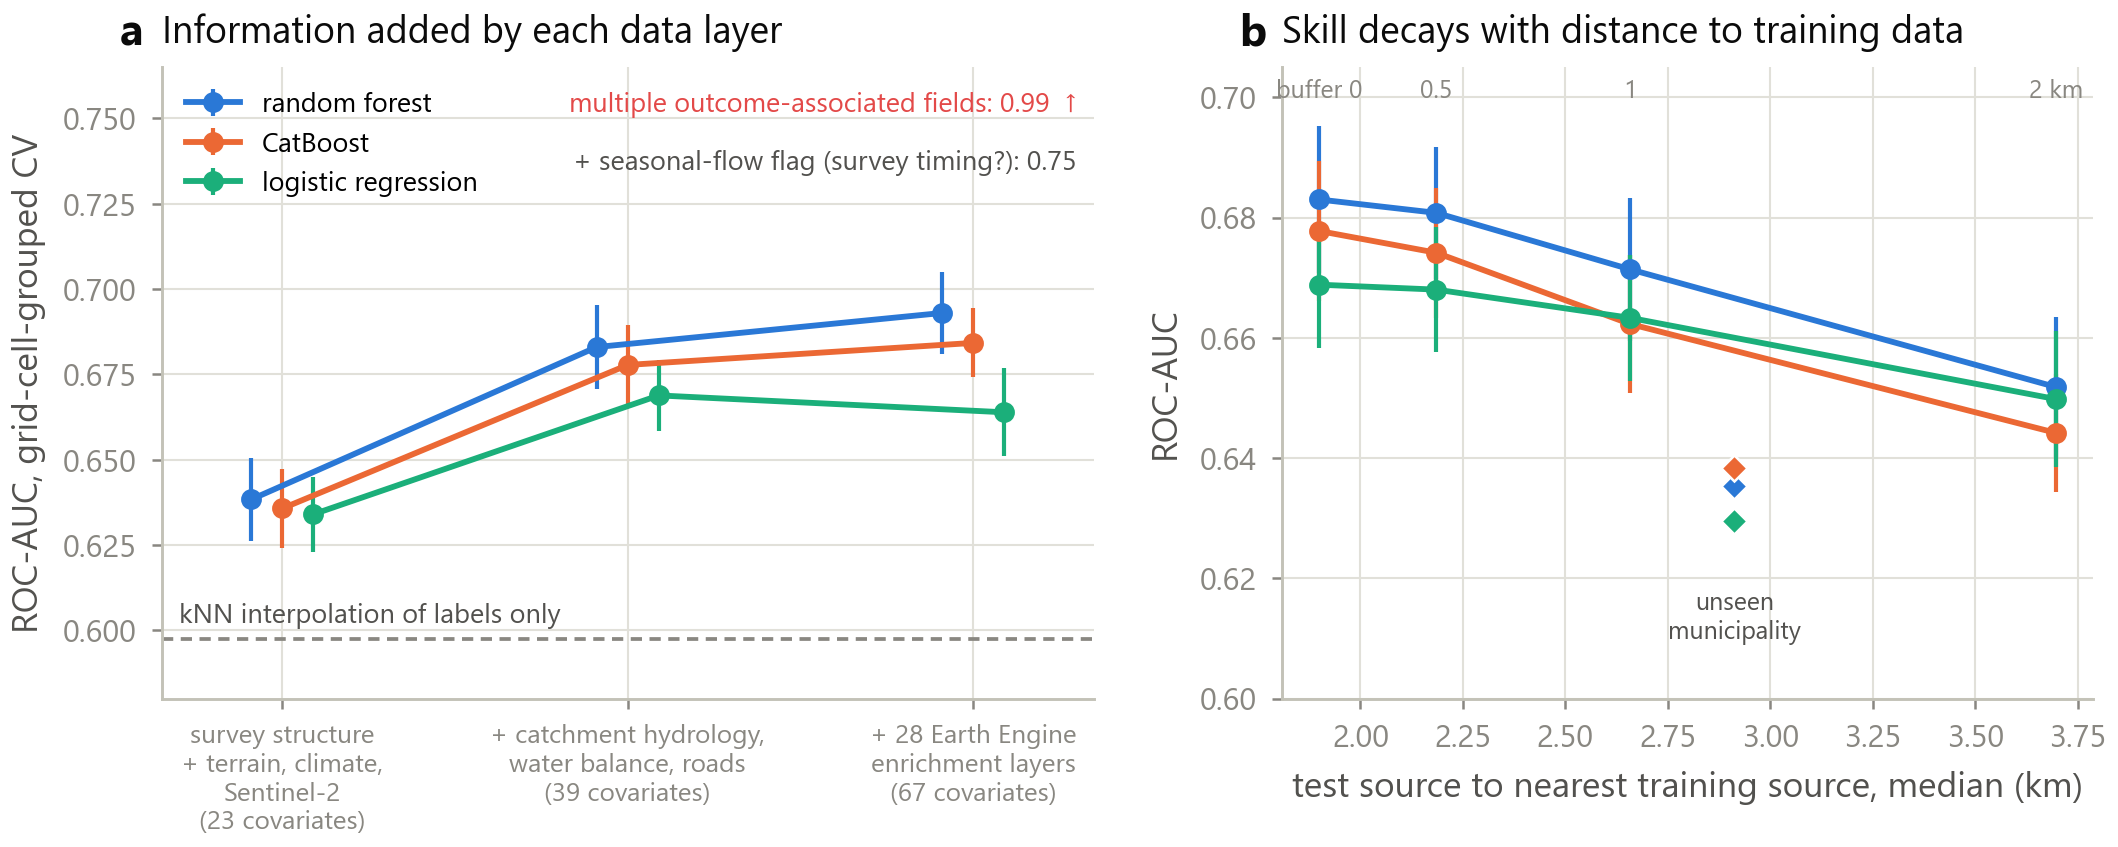

In [10]:
fig("fig2_information.png")